# 01 - EDA: Structural Damage Classification
Tujuan: memahami data sebelum modeling (distribusi target, missing value, anomali, pengaruh lokasi, dan struktur bangunan).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
sys.path.insert(0, str(Path.cwd().parent))  # agar `scripts` bisa di-import dari folder notebooks/
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scripts.config import *
from scripts.preprocess import load_data, encode_target
sns.set_theme(style='whitegrid')
train, test = load_data()
print(train.shape, test.shape)
train.head()

(533465, 17) (228629, 16)


,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


## 1. Distribusi target
Kelas tidak seimbang: Grade 5 paling dominan, Grade 1 dan 2 paling sedikit.

damage_grade
Grade 1    0.103
Grade 2    0.114
Grade 3    0.179
Grade 4    0.241
Grade 5    0.362
Name: proportion, dtype: float64


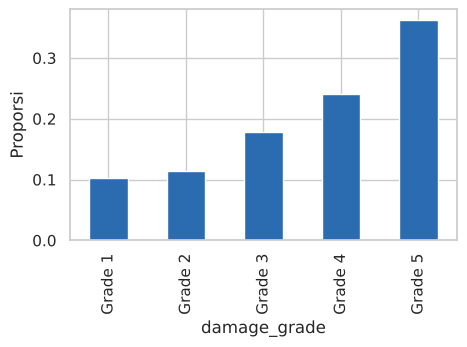

In [2]:
vc = train[TARGET].value_counts(normalize=True).sort_index()
print(vc.round(3))
vc.plot.bar(color='#2b6cb0', figsize=(5,3)); plt.ylabel('Proporsi'); plt.show()

## 2. Missing value dan anomali

In [3]:
print('Missing train:', train.isna().sum().sum(), '| test:', test.isna().sum().sum())
print('age_building == 999 -> train: %.2f%%, test: %.2f%%' % ((train.age_building==999).mean()*100, (test.age_building==999).mean()*100))
train[NUM_COLS].describe().T

Missing train: 0 | test: 0
age_building == 999 -> train: 0.41%, test: 0.41%


,count,mean,std,min,25%,50%,75%,max
count_floors_pre_eq,533465.0,2.088000,0.655001,1.0,2.0,2.0,2.0,9.0
age_building,533465.0,24.337319,64.999055,0.0,9.0,16.0,27.0,999.0
plinth_area_sq_ft,533465.0,406.523453,226.610477,70.0,280.0,358.0,470.0,5000.0
height_ft_pre_eq,533465.0,16.047675,5.490926,6.0,12.0,16.0,18.0,99.0


Tidak ada missing value, tetapi `age_building = 999` adalah kode placeholder (sekitar 0.4%). Di pipeline nilainya diganti NaN lalu di-impute median, ditambah flag `age_is_999`.

## 3. Pengaruh lokasi
Tingkat kerusakan sangat berbeda antar district, jadi fitur geografi penting.

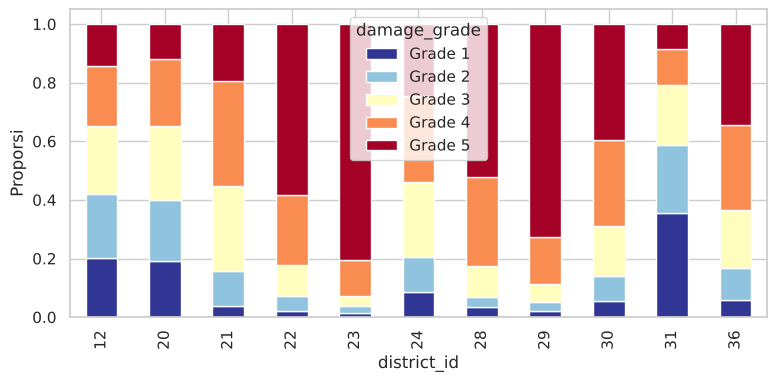

Ward di test yang tidak ada di train: 0


In [4]:
g = train.groupby('district_id')[TARGET].value_counts(normalize=True).unstack().round(3)
ax = g.plot.bar(stacked=True, figsize=(9,4), colormap='RdYlBu_r'); ax.set_ylabel('Proporsi'); plt.show()
print('Ward di test yang tidak ada di train:', len(set(test.ward_id)-set(train.ward_id)))

Semua ward di test juga muncul di train, jadi **target encoding** pada ward/vdc/district aman dan informatif.

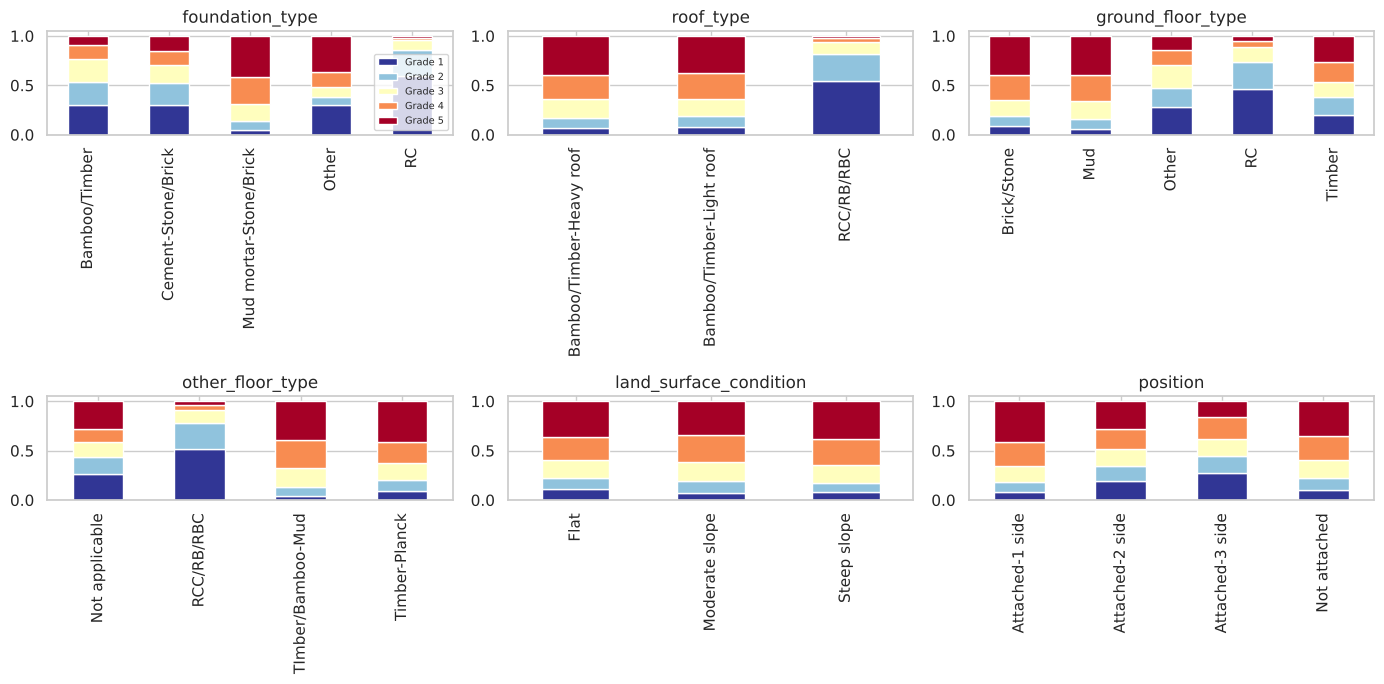

In [5]:
order = CLASSES
fig, axes = plt.subplots(2, 3, figsize=(14,7))
for ax, c in zip(axes.ravel(), ['foundation_type','roof_type','ground_floor_type','other_floor_type','land_surface_condition','position']):
    train.groupby(c)[TARGET].value_counts(normalize=True).unstack()[order].plot.bar(stacked=True, ax=ax, legend=False, colormap='RdYlBu_r')
    ax.set_title(c); ax.set_xlabel('')
axes[0,0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 4. Fitur numerik vs kerusakan

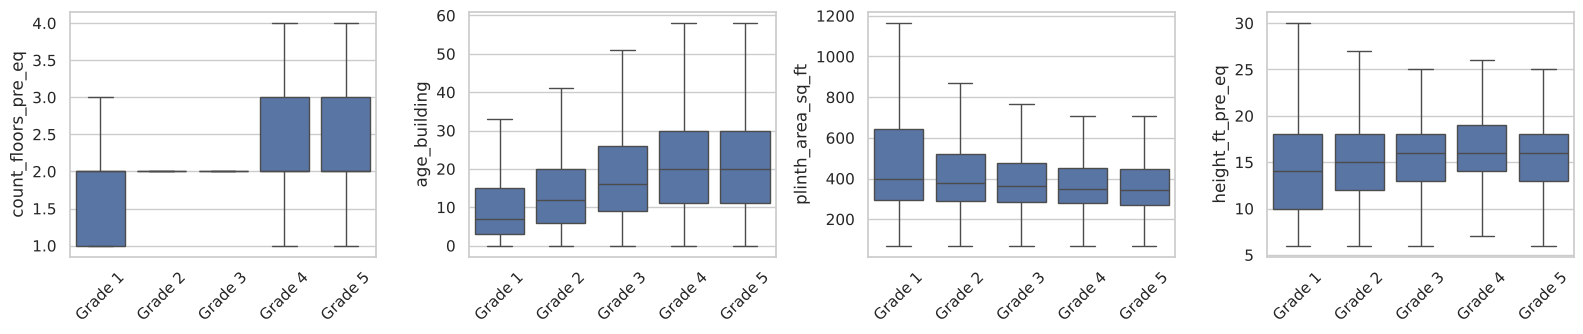

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16,3.5))
for ax, c in zip(axes, NUM_COLS):
    d = train[train.age_building<999] if c=='age_building' else train
    sns.boxplot(data=d, x=TARGET, y=c, order=CLASSES, ax=ax, showfliers=False); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

## 5. building_id dan tetangga
`building_id` berurutan mengikuti urutan survei. Kalau bangunan yang ID-nya berdekatan punya kerusakan mirip (di luar efek ward), label train di sekitar sebuah bangunan test bisa jadi fitur.

In [ ]:
s = train.sort_values('building_id').reset_index(drop=True)
y = s[TARGET].str[-1].astype(int).values
same = s.ward_id.values[1:] == s.ward_id.values[:-1]
r_real = np.corrcoef(y[:-1][same], y[1:][same])[0, 1]
rng = np.random.default_rng(0)
y_shuf = s.assign(y=y).groupby('ward_id')['y'].transform(lambda v: rng.permutation(v.values)).values
r_shuf = np.corrcoef(y_shuf[:-1][same], y_shuf[1:][same])[0, 1]
print(f'Korelasi grade bangunan berurutan (satu ward): {r_real:.3f}')
print(f'Setelah label diacak di dalam ward (hanya efek ward): {r_shuf:.3f}')

Korelasi 0.58 vs 0.45: ada sinyal lokal tambahan di luar efek ward. Ini dipakai oleh `NeighborTargetFeatures` (`scripts/neighbor_features.py`), yang menghitung rata-rata label tetangga terdekat menurut `building_id`, dengan skema leave-one-out pada data train agar label tidak bocor.

## 6. Ringkasan temuan
- Target 5 kelas, tidak seimbang (Grade 5 sekitar 36%).
- Tidak ada missing value; `age_building = 999` adalah placeholder.
- Lokasi (district/ward) dan material (foundation, ground floor, superstructure) sangat membedakan tingkat kerusakan.
- Bangunan dengan `building_id` berdekatan punya kerusakan yang mirip, di luar efek ward.
- Distribusi train dan test seragam dan seluruh ward test ada di train (split acak).